<a href="https://colab.research.google.com/github/syifaST/simuteh--2330511062-/blob/main/notebook/P5__tepi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys
REPO = "https://github.com/syifaST/simuteh--2330511062-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

perlu = ["citra", "bersih", "mask_daun", "mask_bercak"]
if (not all(os.path.exists(f"data/sintetis/{d}") for d in perlu)
        or not os.path.exists("data/sintetis/label.csv")):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Isi src:", os.listdir("../src"))
print("Param ada:", os.path.exists("../hasil/param_praproses.json"))

Folder kerja: /content/simuteh/notebook
Isi src: ['praproses.py', '__pycache__', 'utils_tepi.py', 'utils_cv.py', 'buat_dataset_sintetis.py']
Param ada: True


## **KODE 1.1**

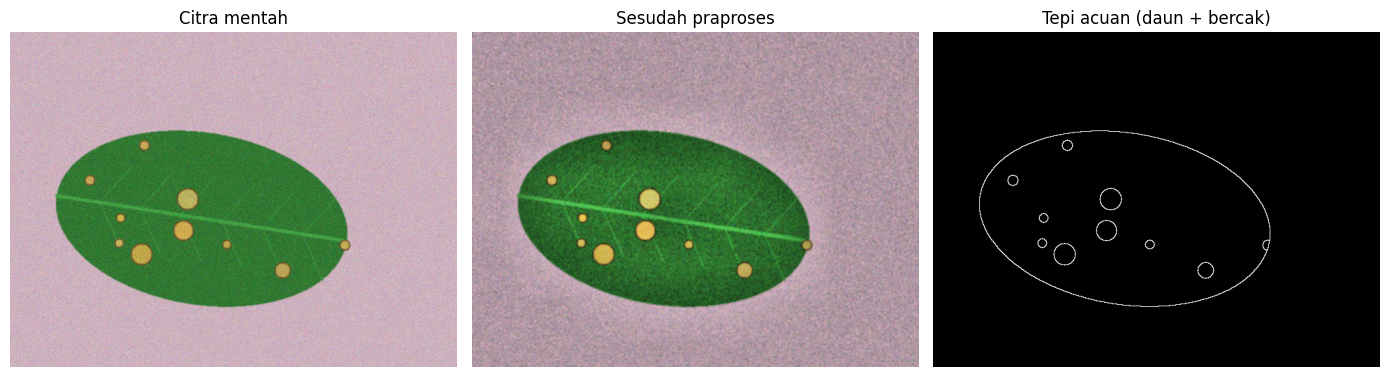

In [ ]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
plt.savefig("../hasil/p5_acuan.png"); plt.show()

## **KODE 1.2**

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 676.1


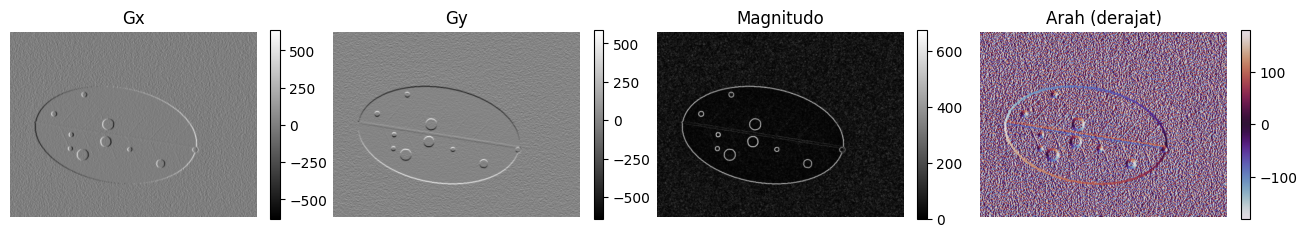

In [ ]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"),
                             (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.savefig("../hasil/p5_gradien.png"); plt.show()

## **KODE 1.3**

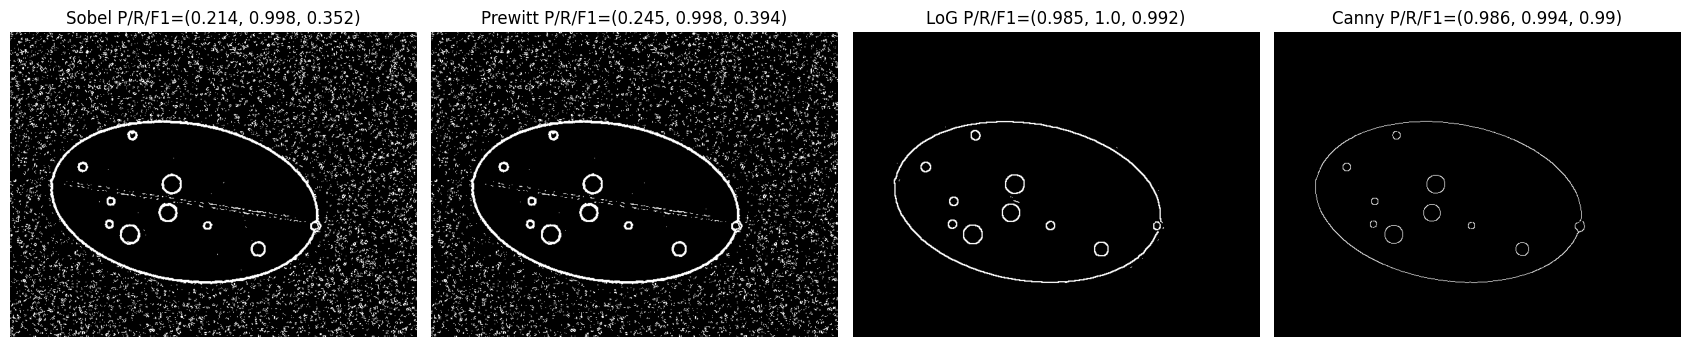

In [ ]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()),
       [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png"); plt.show()

## **KODE 1.4**

In [ ]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.757  0.751  0.753
                LoG      0.649  0.997  0.782
                Prewitt  0.821  0.958  0.873
                Sobel    0.796  0.964  0.860
          R     Canny    0.986  0.982  0.983
                LoG      0.901  0.997  0.943
                Prewitt  0.599  0.995  0.713
                Sobel    0.521  0.996  0.644
praproses Gray  Canny    0.680  0.948  0.785
                LoG      0.567  0.997  0.719
                Prewitt  0.585  0.996  0.729
                Sobel    0.553  0.996  0.701
          R     Canny    0.933  0.990  0.957
                LoG      0.837  0.997  0.901
                Prewitt  0.459  0.997  0.600
                Sobel    0.408  0.997  0.550


## **KODE 2.1**

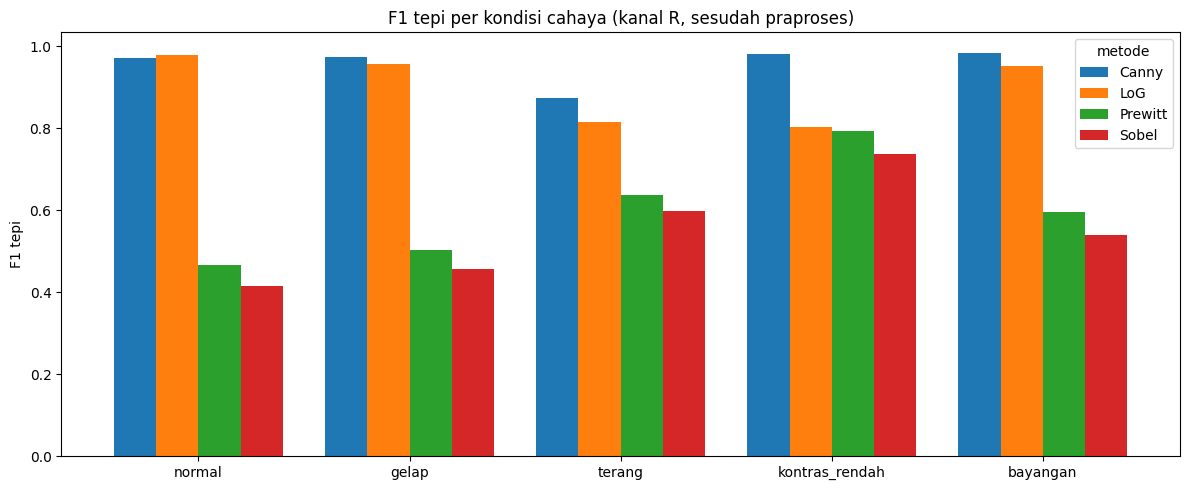

In [ ]:
urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
f1k = (tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
       .groupby(["kondisi", "metode"]).F1.mean().unstack("metode").loc[urut])
ax = f1k.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_ylabel("F1 tepi"); ax.set_xlabel("")
ax.set_title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150); plt.show()

## **KODE 2.1**

In [ ]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]       # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))
canny.to_csv("../hasil/p5_canny.csv", index=False)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.526  0.994  0.636     0.981
      30/90    0.019  0.997  0.037     0.992
      50/150   0.091  0.995  0.152     0.984
1.0   100/200  0.975  0.993  0.984     0.977
      30/90    0.233  0.994  0.333     0.979
      50/150   0.880  0.994  0.927     0.978
2.0   100/200  0.841  0.825  0.832     0.742
      30/90    0.933  0.990  0.957     0.960
      50/150   0.981  0.959  0.959     0.918
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.974   0.987
      30/90    0.989   0.995
      50/150   0.980   0.988
1.0   100/200  0.973   0.981
      30/90    0.977   0.981
      50/150   0.976   0.981
2.0   100/200  0.755   0.729
      30/90    0.953   0.966
      50/150   0.931   0.904


## **KODE 2.2**


In [ ]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
                      skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
                      skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.499  0.592           0.910   0.717   0.837
      tetap 30/90     0.762  0.746           0.916   0.750   0.748
R     otomatis        0.282  0.516           0.931   0.732   0.917
      tetap 30/90     0.985  0.974           0.981   0.971   0.875
kanal  kondisi       
Gray   bayangan          115.1
       gelap             132.5
       kontras_rendah    151.4
       normal            163.8
       terang            196.1
R      bayangan          121.4
       gelap             149.8
       kontras_rendah    154.0
       normal            177.2
       terang            200.1
Name: median, dtype: float64


## **2.4**

In [ ]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """Ambang Canny dari persentil ke-q magnitudo gradien Sobel."""
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)            # (1) haluskan dengan Gaussian
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx ** 2 + gy ** 2)                         # (2) magnitudo Sobel (norma L1, sama dengan cv2.Canny)
    hi = float(np.percentile(mag, q))                     # (3) ambang atas = persentil ke-q
    lo = rasio * hi                                       #     ambang bawah = rasio x ambang atas
    return cv2.Canny(g, lo, hi)                           # (4) citra sudah halus, tidak diburamkan lagi

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"persentil {q}",
                          skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
semua = pd.concat([auto[["kondisi", "kanal", "ambang", "F1"]], pers])
print(semua.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
semua.to_csv("../hasil/p5_ambang_otomatis.csv", index=False)

kondisi             bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                       
Gray  otomatis         0.499  0.592           0.910   0.717   0.837
      persentil 90     0.063  0.058           0.059   0.062   0.057
      persentil 95     0.273  0.247           0.139   0.352   0.276
      persentil 98     0.750  0.741           0.738   0.750   0.735
      tetap 30/90      0.762  0.746           0.916   0.750   0.748
R     otomatis         0.282  0.516           0.931   0.732   0.917
      persentil 90     0.069  0.060           0.060   0.065   0.059
      persentil 95     0.150  0.081           0.128   0.170   0.262
      persentil 98     0.987  0.980           0.930   0.989   0.855
      tetap 30/90      0.985  0.974           0.981   0.971   0.875


## **KODE 2.3**

kanal            Gray      R
kondisi                     
bayangan        799.5    0.0
gelap           884.2    0.0
kontras_rendah  156.8    0.0
normal          878.2    0.0
terang          884.2  191.0


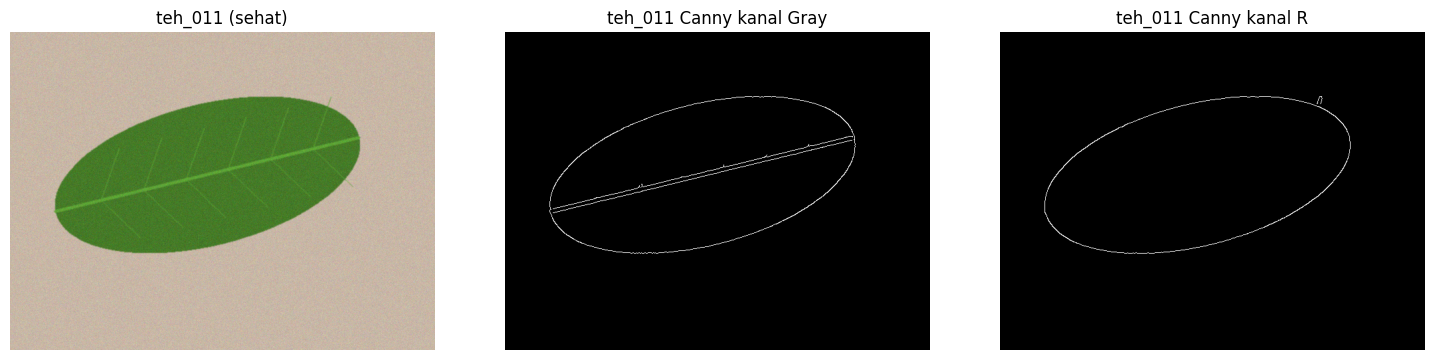

In [ ]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0      # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
                        values="piksel_tepi_di_dalam_daun").round(1))
sehat.to_csv("../hasil/p5_tepi_sehat.csv", index=False)
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_sehat.png"); plt.show()